# Potencia frente a PD subestimadas y las probabilidades de rechazo exactas que no necesitan simulación

- **Nivel:** 2, El método en la práctica
- **Requisitos previos:** los cuadernos 01 y 02 de este tema (la tasa y su error de Monte Carlo, el tamaño de cada prueba)
- **Tiempo de lectura:** unos 50 minutos

## Objetivos

Al terminar este cuaderno puedes:

- plantar una descalibración de severidad conocida (cada PD verdadera es $k$ veces la PD aplicada) y leer la potencia de cada prueba de calibración frente a ella, con su error de Monte Carlo;
- calcular con el motor la probabilidad de rechazo exacta de las pruebas de conteo y de la prueba de semáforo, contrastar con ella las tasas simuladas, y decir dónde concuerdan;
- encontrar por búsqueda de raíces la severidad que una prueba detecta con 80% de potencia, y reproducir la razón versionada de 1,2587 para la prueba de Jeffreys;
- explicar por qué la prueba binomial con corrección de Vasicek renuncia a su potencia, y por qué la prueba del perfil de incumplimiento no puede ver una subestimación uniforme.

## Preparación

Instala una vez el entorno fijado, en un entorno virtual, con el comando de siempre:

```bash
pip install -r notebooks/requirements.txt
```

o solo los paquetes que usa este cuaderno, con las mismas versiones exactas:

```bash
pip install riskvalidation==1.0.0 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` en Windows) construye `.venv-notebooks` por ti. La celda siguiente importa los paquetes e imprime sus versiones.

In [1]:
# Importar las herramientas e imprimir las versiones con que corren, para compararlas con notebooks/requirements.txt
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv
from scipy import optimize

for name in ("riskvalidation", "numpy", "scipy", "matplotlib"):
    print(name, md.version(name))

riskvalidation 0.9.0
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Datos

Los datos son la familia `miscalibration` del caso C22 (validar al validador): cada conjunto se sortea con un generador de verdad conocida de `riskvalidation.generators` (licencia MIT, clase `generated`), y en todos las PD que recibe la prueba son $1/k$ de las PD verdaderas, con $k$ en la escalera 1; 1,1; 1,25; 1,5; 2 y 3. La escalera es una elección de diseño de Contraste, elegida para que las curvas de potencia vayan del tamaño a casi uno; no es una afirmación sobre ningún banco. Con $k = 1$ la nula se cumple, así que el primer peldaño de cada curva es un tamaño.

- **Archivo que se lee:** `data/derived/C22/miscalibration.json`: `outputs.simulations` (54 filas: nueve pruebas sobre seis peldaños, 2.000 repeticiones cada una), `outputs.generators` (configuración y verdad de cada uno), `outputs.panels`, `outputs.ladder` e `impact`.
- **Paneles:** `portfolio` (pruebas de conteo con 5.000 deudores y PD de 2%), `grades` (siete grados), `obligors` (un modelo logístico de 5.000 deudores) y `years` (cinco años de 1.000 deudores al 3%).

La celda siguiente carga el artefacto e imprime la escalera, los paneles y lo que mide cada panel.

In [2]:
# Cargar la familia de descalibración, indexar sus filas por clave e imprimir la escalera y los paneles
LANG = "es"
ROOT = Path("../../..").resolve()
miscal = json.loads((ROOT / "data" / "derived" / "C22" / "miscalibration.json").read_text(encoding="utf-8"))
out = miscal["outputs"]
rows = {row["key"]: row for row in out["simulations"]}
ladder = out["ladder"]["values"]

print("calculado por riskvalidation", miscal["provenance"]["riskvalidation_version"], "|", "instalado", rv.__version__)
print("escalera:", out["ladder"]["label"][LANG], ladder)
measure_name = {"size": "tamaño", "power": "potencia"}
for panel in out["panels"]:
    n_rows = sum(1 for row in rows.values() if row["panel"] == panel["id"])
    print(f"{panel['label'][LANG]:34s} {n_rows} filas | mide: {measure_name[panel['measures']]}")

calculado por riskvalidation 0.4.3 | instalado 0.9.0
escalera: PD verdadera / PD aplicada [1.0, 1.1, 1.25, 1.5, 2.0, 3.0]
Pruebas de conteo de cartera       18 filas | mide: potencia
Pruebas por grado                  12 filas | mide: potencia
Pruebas por deudor                 12 filas | mide: potencia
Pruebas multianuales               12 filas | mide: potencia


## Método

La potencia de una prueba frente a un defecto es su probabilidad de rechazo cuando el defecto está presente. El caso la estima como una tasa de rechazo sobre 2.000 repeticiones (Morris, White y Crowther, 2019, Tabla 6), con nivel 5%, y para las pruebas que ven los datos solo a través de un conteo de incumplimientos la calcula además de forma exacta. Con $D \sim \mathrm{Binomial}(n, \pi)$ incumplimientos entre $n$ deudores, una prueba de conteo rechaza exactamente cuando $D \ge k^*_\alpha$, el menor conteo cuyo valor p bajo la PD aplicada es menor que $\alpha$ (el motor lo encuentra llamando a la prueba registrada). Bajo la PD verdadera $\pi = k\cdot\mathrm{PD}$ la potencia es una cola binomial:

$$\text{potencia}(k) = P\big(D \ge k^*_\alpha\big), \qquad D \sim \mathrm{Binomial}\big(n,\; k\cdot \mathrm{PD}_{\text{aplicada}}\big)$$

La prueba de semáforo necesita la distribución de su perfil de colores a lo largo de los años, que el motor construye por convolución, también sin simulación. Los pasos plantan el defecto, leen la potencia simulada, calculan al lado la potencia exacta, encuentran la severidad de 80% de potencia, y luego leen las pruebas que se comportan distinto.

### Paso 1: el defecto plantado, sobre un conjunto

El generador detrás de `pd.binomial@k1.5` es `default_counts`: 5.000 deudores, una PD verdadera de 3% y una PD aplicada de 2%. Su verdad dice qué se plantó: 150 incumplimientos esperados donde la PD aplicada espera 100, y `calibration_null_holds` falso. La celda siguiente reconstruye el generador desde la configuración versionada, sortea un conjunto y corre sobre él las pruebas binomial y de Jeffreys, como las correría un validador con un año de datos.

In [3]:
# Reconstruir el generador del peldaño k = 1,5, leer su verdad, sortear un conjunto y correr dos pruebas sobre él
from riskvalidation.generators import DefaultCounts, feed_cell
from riskvalidation.validation import pd_binomial, pd_jeffreys

spec = out["generators"]["port-5000-k1.5"]
truth = spec["truth"]
print("PD verdadera:", truth["pd_true"][0][0], "|", "PD aplicada:", truth["pd_forecast"][0][0], "|", "incumplimientos esperados:", truth["expected_defaults"][0][0],
      "|", "esperados con la PD aplicada:", truth["obligors"][0][0] * truth["pd_forecast"][0][0])
print("la nula se cumple:", ("sí" if truth["calibration_null_holds"] else "no"))

generator = DefaultCounts(**spec["config"])
cell = feed_cell()(generator.draw(np.random.default_rng(5)))
print("un conjunto: deudores", cell["n"], "|", "incumplimientos", cell["d"])
for test in (pd_binomial, pd_jeffreys):
    result = test(**cell)
    print(f"{result.test_id:12s} valor p {result.p_value:.3e} | luz {result.light.value}")

PD verdadera: 0.03 | PD aplicada: 0.02 | incumplimientos esperados: 150.0 | esperados con la PD aplicada: 100.0
la nula se cumple: no
un conjunto: deudores 5000 | incumplimientos 159
pd.binomial  valor p 2.312e-08 | luz red
pd.jeffreys  valor p 1.809e-08 | luz red


### Paso 2: la potencia de las pruebas de conteo en la cartera

El panel `portfolio` corre tres pruebas de conteo sobre 5.000 deudores con PD de 2%: la prueba binomial, la de Jeffreys y la binomial corregida por una correlación de activos de 12% (`pd.binomial_vasicek`). Cada fila trae la tasa simulada al 5%, su probabilidad exacta y una marca `agrees`. La celda siguiente imprime tasa y valor exacto lado a lado a lo largo de la escalera, y recalcula la concordancia con la función `agrees` del motor sobre los conteos versionados.

In [4]:
# Imprimir la tasa simulada y la potencia exacta de las tres pruebas de conteo a lo largo de la escalera y recalcular la concordancia
from riskvalidation.harness import Rate, agrees

count_tests = ("pd.binomial", "pd.jeffreys", "pd.binomial_vasicek")
print(f"{'k':>5s} " + " ".join(f"{t.split('.')[1][:14]:>16s}" for t in count_tests) + "   (simulada / exacta, nivel 5%)")
agreeing, compared = 0, 0
for k in ladder:
    cells = []
    for test in count_tests:
        row = rows[f"{test}@k{k:g}"]
        c = row["rates"]["p<0.05"]
        cells.append(f"{c['rate']:.3f} / {row['exact']['p<0.05']:.3f}")
        for rule in ("p<0.05", "p<0.01"):
            cc = row["rates"][rule]
            compared += 1
            agreeing += agrees(Rate(cc["rejections"], cc["n"]), row["exact"][rule])
    print(f"{k:5.2f} " + " ".join(f"{c:>16s}" for c in cells))
print("tasas simuladas que concuerdan con su valor exacto (ambos niveles):", agreeing, "de", compared)

    k         binomial         jeffreys   binomial_vasic   (simulada / exacta, nivel 5%)
 1.00    0.038 / 0.041    0.047 / 0.050    0.000 / 0.000
 1.10    0.228 / 0.233    0.247 / 0.262    0.000 / 0.000
 1.25    0.760 / 0.749    0.797 / 0.778    0.000 / 0.000
 1.50    0.996 / 0.997    0.999 / 0.998    0.000 / 0.000
 2.00    1.000 / 1.000    1.000 / 1.000    0.000 / 0.000
 3.00    1.000 / 1.000    1.000 / 1.000    0.790 / 0.788
tasas simuladas que concuerdan con su valor exacto (ambos niveles): 36 de 36


### Paso 3: la potencia exacta, calculada aquí

`rejection_probability` encuentra el conteo crítico llamando a la prueba y devuelve la cola binomial de la fórmula anterior. La celda siguiente recalcula la potencia exacta al 5% de las tres pruebas de conteo a lo largo de la escalera, imprime el conteo crítico que necesita cada prueba (frente a los 100 incumplimientos que espera la PD aplicada) y compara el resultado con los valores exactos que guardó el artefacto. La prueba de Vasicek necesita un conteo mucho mayor porque supone que los incumplimientos de un deudor están correlacionados, lo que ensancha la distribución del conteo que debe tolerar.

In [5]:
# Recalcular la potencia exacta de las pruebas de conteo a lo largo de la escalera y compararla con los valores exactos versionados
from riskvalidation.harness import rejection_probability

extra = {"pd.binomial": {}, "pd.jeffreys": {}, "pd.binomial_vasicek": {"rho": 0.12}}
largest_gap = 0.0
for test in count_tests:
    powers = []
    for k in ladder:
        exact = rejection_probability(test, 5000, 0.02, 0.05, pd_true=0.02 * k, **extra[test])
        powers.append(exact["probability"])
        largest_gap = max(largest_gap, abs(exact["probability"] - rows[f"{test}@k{k:g}"]["exact"]["p<0.05"]))
    print(f"{test:20s} conteo crítico {exact['critical_count']:4d} | potencia exacta a lo largo de la escalera", [round(p, 4) for p in powers])
print("mayor brecha con los valores exactos versionados:", f"{largest_gap:.2e}")

pd.binomial          conteo crítico  118 | potencia exacta a lo largo de la escalera [0.0413, 0.2325, 0.7491, 0.9973, 1.0, 1.0]
pd.jeffreys          conteo crítico  117 | potencia exacta a lo largo de la escalera [0.0505, 0.2624, 0.7776, 0.998, 1.0, 1.0]
pd.binomial_vasicek  conteo crítico  287 | potencia exacta a lo largo de la escalera [0.0, 0.0, 0.0, 0.0, 0.0, 0.7884]
mayor brecha con los valores exactos versionados: 4.54e-10


### Paso 4: la severidad de 80% de potencia

El resultado principal versionado `jeffreys_k80` es la razón de PD verdadera a aplicada con la que la prueba de Jeffreys tiene 80% de potencia. Como la potencia exacta es una función suave de $k$ salvo por la discretización del conteo crítico, un buscador de raíces la ubica: el $k$ donde $\text{potencia}(k) - 0{,}8$ cambia de signo. La celda siguiente llama a `brentq` de SciPy sobre la potencia exacta del motor, sin simulación, y compara la raíz con el valor versionado. Luego hace la misma pregunta a la prueba binomial, para decir cuánto debe estar baja una PD antes de que un validador que corre la prueba binomial la vea más veces de las que no.

In [6]:
# Encontrar la severidad de 80% de potencia con un buscador de raíces sobre la potencia exacta del motor, para Jeffreys y para la binomial
def power_gap(k, test):
    return rejection_probability(test, 5000, 0.02, 0.05, pd_true=0.02 * k)["probability"] - 0.8

k80 = {test: optimize.brentq(power_gap, 1.0, 3.0, args=(test,), xtol=1e-12) for test in ("pd.jeffreys", "pd.binomial")}
print("Jeffreys, k con 80% de potencia:", round(k80["pd.jeffreys"], 6), "|", "versionado:", miscal["impact"]["jeffreys_k80"]["value"])
print("binomial, k con 80% de potencia:", round(k80["pd.binomial"], 6))
print("el resultado versionado es la razón de PD verdadera a aplicada con 80% de potencia (5000 deudores, PD 2%):", round(miscal["impact"]["jeffreys_k80"]["value"], 6))

Jeffreys, k con 80% de potencia: 1.258663 | versionado: 1.25866292
binomial, k con 80% de potencia: 1.269036
el resultado versionado es la razón de PD verdadera a aplicada con 80% de potencia (5000 deudores, PD 2%): 1.258663


### Paso 5: lo que cuesta la corrección de Vasicek

La prueba binomial del BCE trata a los deudores como independientes. La versión con corrección de Vasicek acepta que los incumplimientos comparten un factor sistemático, con una correlación de activos supuesta de 12%, y ensancha su conteo crítico en consecuencia (paso 3). En estos datos los incumplimientos son independientes, de modo que la corrección protege contra un riesgo que no está, y lo que cuesta es potencia. La celda siguiente calcula la potencia exacta de la prueba corregida con severidades mayores, donde terminan los seis peldaños del artefacto, y encuentra la severidad en que llega a 80%.

In [7]:
# Potencia exacta de la prueba con corrección de Vasicek más allá de la escalera versionada, y su severidad de 80% de potencia
for k in (2.5, 3.0, 3.5, 4.0):
    power = rejection_probability("pd.binomial_vasicek", 5000, 0.02, 0.05, pd_true=0.02 * k, rho=0.12)["probability"]
    print(f"k = {k:3.1f} | potencia exacta de la prueba corregida {power:.4f}")

def vasicek_gap(k):
    return rejection_probability("pd.binomial_vasicek", 5000, 0.02, 0.05, pd_true=0.02 * k, rho=0.12)["probability"] - 0.8

k80_vasicek = optimize.brentq(vasicek_gap, 2.0, 4.0, xtol=1e-12)
print("prueba corregida, k con 80% de potencia:", round(k80_vasicek, 4), "|", "binomial:", round(k80["pd.binomial"], 4))

k = 2.5 | potencia exacta de la prueba corregida 0.0100
k = 3.0 | potencia exacta de la prueba corregida 0.7884
k = 3.5 | potencia exacta de la prueba corregida 0.9999
k = 4.0 | potencia exacta de la prueba corregida 1.0000
prueba corregida, k con 80% de potencia: 3.0069 | binomial: 1.269


### Paso 6: las otras pruebas, simuladas

Los otros tres paneles no tienen forma cerrada salvo el semáforo. El panel `grades` corre el chi-cuadrado sobre siete grados y la prueba del perfil de incumplimiento, el panel `obligors` corre Hosmer-Lemeshow y Spiegelhalter sobre un modelo logístico cuyas razones de chances se dividen por $k$, y el panel `years` corre la prueba normal multianual y el semáforo en cinco años con PD de 3%. La celda siguiente imprime su potencia simulada a lo largo de la escalera con el valor exacto de la prueba de semáforo junto al versionado. El rechazo en $k = 1$ es el tamaño.

In [8]:
# Imprimir la potencia simulada de las pruebas por grado, por deudor y por año a lo largo de la escalera, con la potencia exacta del semáforo junto a la versionada
from riskvalidation.harness import traffic_lights_rejection_probability

others = ("pd.chi2_grades", "pd.default_profile", "pd.hosmer_lemeshow", "pd.spiegelhalter", "pd.normal_multiperiod", "pd.traffic_lights")
print(f"{'k':>5s} " + " ".join(f"{t.split('.')[1][:11]:>12s}" for t in others) + f" {'SM exacta':>9s}")
for k in ladder:
    rates = [rows[f"{t}@k{k:g}"]["rates"]["p<0.05"]["rate"] for t in others]
    exact_tl = traffic_lights_rejection_probability([1000] * 5, 0.03, 0.05, pd_true=0.03 * k)["probability"]
    stored_tl = rows[f"pd.traffic_lights@k{k:g}"]["exact"]["p<0.05"]
    print(f"{k:5.2f} " + " ".join(f"{r:12.3f}" for r in rates) + f" {exact_tl:9.4f}", "(versionado", f"{stored_tl:.4f})")

    k  chi2_grades  default_pro  hosmer_leme  spiegelhalt  normal_mult  traffic_lig SM exacta
 1.00        0.053        0.033        0.050        0.053        0.077        0.043    0.0379 (versionado 0.0379)
 1.10        0.160        0.038        0.168        0.412        0.370        0.278    0.2521 (versionado 0.2521)
 1.25        0.661        0.037        0.649        0.946        0.863        0.806    0.8019 (versionado 0.8019)
 1.50        0.995        0.036        0.995        1.000        1.000        1.000    0.9985 (versionado 0.9985)
 2.00        1.000        0.033        1.000        1.000        1.000        1.000    1.0000 (versionado 1.0000)
 3.00        1.000        0.024        1.000        1.000        1.000        1.000    1.0000 (versionado 1.0000)


### Paso 7: la prueba del perfil es ciega al nivel

La prueba del perfil de incumplimiento compara la forma de los incumplimientos observados en los grados con la forma que implican las PD, y no su nivel (el hallazgo `F-PROFILE-BLIND` del artefacto). Si toda PD está baja por el mismo factor, la forma no cambia. La celda siguiente imprime la tasa de la prueba a lo largo de la escalera junto al chi-cuadrado por grados, que sí ve el nivel, y el texto del hallazgo desde el artefacto.

In [9]:
# Comparar la prueba del perfil con el chi-cuadrado por grados e imprimir el hallazgo del artefacto
for test in ("pd.default_profile", "pd.chi2_grades"):
    rates = [rows[f"{test}@k{k:g}"]["rates"]["p<0.05"]["rate"] for k in ladder]
    print(f"{test:20s}", [round(r, 3) for r in rates])
finding = next(f for f in miscal["findings"] if f["id"] == "F-PROFILE-BLIND")
status_name = {"accepted": "aceptado", "closed": "cerrado", "open": "abierto"}
print(finding["id"], finding["severity"], status_name[finding["status"]], "|", finding["title"][LANG])

pd.default_profile   [0.033, 0.038, 0.037, 0.036, 0.033, 0.024]
pd.chi2_grades       [0.053, 0.16, 0.661, 0.995, 1.0, 1.0]
F-PROFILE-BLIND S4 aceptado | La prueba del perfil ve la forma de la curva de PD, no su nivel: una subestimación uniforme la deja en su tamaño


### Paso 8: las curvas de potencia, dibujadas

La última celda dibuja los cuatro paneles. Cada punto es una tasa simulada con su intervalo de Wilson, las cruces son la potencia exacta de las pruebas de conteo y del semáforo calculada arriba y guardada en el artefacto, y la línea discontinua es el 5% nominal. Una curva que parte en 5% con $k = 1$ y sube a 1 es una prueba que mantiene su tamaño y tiene potencia; una curva que parte cerca de 0 es conservadora, y una que queda plana es ciega.

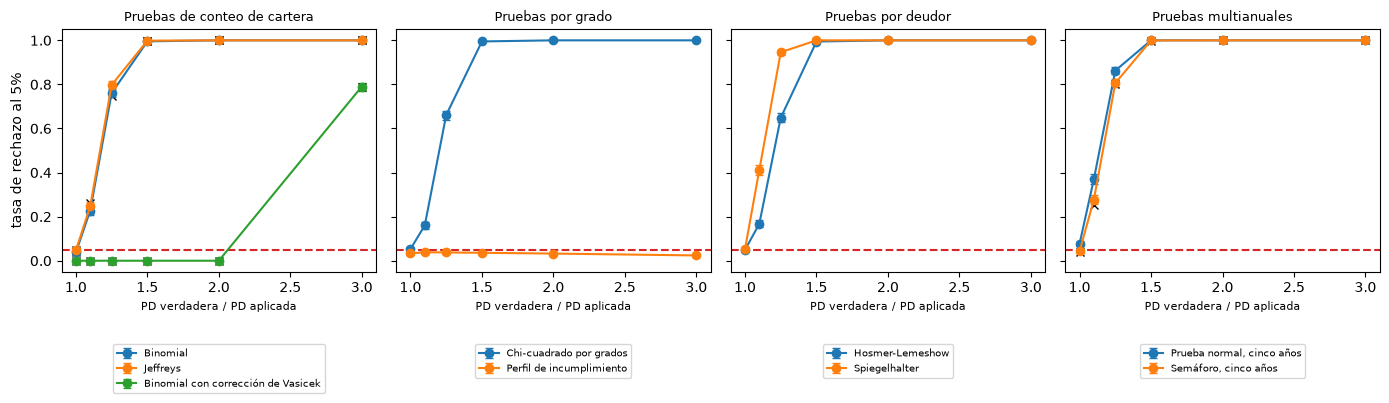

In [10]:
# Dibujar la potencia simulada con intervalos de Wilson y la potencia exacta de los cuatro paneles
panel_tests = {"portfolio": count_tests, "grades": ("pd.chi2_grades", "pd.default_profile"),
               "obligors": ("pd.hosmer_lemeshow", "pd.spiegelhalter"), "years": ("pd.normal_multiperiod", "pd.traffic_lights")}
fig, axes = plt.subplots(1, 4, figsize=(14, 4.4), sharey=True)
for ax, panel in zip(axes, out["panels"]):
    for index, test in enumerate(panel_tests[panel["id"]]):
        points = [rows[f"{test}@k{k:g}"] for k in ladder]
        rate = np.array([p["rates"]["p<0.05"]["rate"] for p in points])
        low = np.array([p["rates"]["p<0.05"]["wilson_low"] for p in points])
        high = np.array([p["rates"]["p<0.05"]["wilson_high"] for p in points])
        color = f"C{index}"
        ax.errorbar(ladder, rate, yerr=[rate - low, high - rate], fmt="o-", capsize=3, color=color, label=points[0]["label"][LANG])
        if points[0]["exact"] is not None:
            ax.plot(ladder, [p["exact"]["p<0.05"] for p in points], "x", color="black")
    ax.axhline(0.05, color="tab:red", linestyle="--")
    ax.set_title(panel["label"][LANG], fontsize=9)
    ax.set_xlabel(out["ladder"]["label"][LANG], fontsize=8)
    ax.legend(fontsize=7, loc="upper center", bbox_to_anchor=(0.5, -0.28))
axes[0].set_ylabel("tasa de rechazo al 5%")
fig.tight_layout()
plt.show()

## Resultados

- **El defecto se ve en un solo conjunto cuando es suficientemente grande.** Con una PD verdadera de 3% frente a 2% aplicada, un conjunto de 5.000 deudores tuvo 159 incumplimientos donde la PD aplicada espera 100, y las pruebas binomial y de Jeffreys quedaron en rojo (p cercano a 2e-8). La escalera pregunta cuán pequeño puede ser un defecto antes de que eso deje de ser el resultado habitual.
- **Pruebas de conteo: la potencia sube rápido entre 10% y 50% de subestimación.** La prueba binomial rechaza 22,8% de las veces cuando toda PD está 10% baja, 76,0% con 25% baja y 99,6% con 50% baja; la de Jeffreys 24,7%, 79,7% y 99,9%. Los valores exactos son 23,3%, 74,9% y 99,7% para la prueba binomial y 26,2%, 77,8% y 99,8% para la de Jeffreys, y las 36 tasas simuladas concuerdan con su valor exacto.
- **El cálculo exacto reproduce el artefacto.** Recalculada en vivo, la potencia exacta difiere de la guardada en a lo sumo 4,5e-10. La prueba binomial rechaza desde 118 incumplimientos y la de Jeffreys desde 117, frente a 100 esperados, y la severidad de 80% de potencia de la prueba de Jeffreys es 1,258663 frente al 1,25866292 versionado. La prueba binomial necesita una razón de 1,2690. Leído como una afirmación sobre esta cartera: una PD debe estar cerca de 26% baja para que una prueba de Jeffreys sobre 5.000 deudores con PD de 2% la vea cuatro veces de cada cinco.
- **Corregir por una correlación que no existe cuesta la potencia.** La prueba binomial con corrección de Vasicek necesita 287 incumplimientos para rechazar, y en estos datos independientes no rechaza casi nada hasta una razón de 2 (1,0% con 2,5) y llega a 78,8% con una razón de 3 (80% en 3,0069). La corrección es una protección contra el agrupamiento (cuaderno 04), y en datos sin agrupamiento se paga con potencia.
- **El tamaño es parte de la curva.** Con $k = 1$ el tamaño exacto al 5% de la prueba binomial es 4,13% y el de la prueba de Jeffreys 5,05%. La prueba normal multianual parte en 7,7% (cuaderno 02), así que parte de su 37,0% con $k = 1{,}1$ es falsa alarma, no detección. Un número de potencia se lee frente al tamaño del primer peldaño.
- **Las pruebas por deudor no son todas iguales.** Con 25% de subestimación, Spiegelhalter rechaza 94,6% frente a 64,9% de Hosmer-Lemeshow y 66,1% del chi-cuadrado por grados, porque usa a cada deudor en lugar de diez grupos o siete grados. La prueba de semáforo, que no necesita simulación, llega a 80,6% (exacto 80,19%) con cinco años de 1.000 deudores.
- **Una prueba ciega solo se ve por su curva.** La prueba del perfil de incumplimiento queda entre 2,4% y 3,8% en cada peldaño, incluida una PD tres veces baja. Prueba la forma de la curva de PD, no su nivel, como dice el hallazgo del artefacto, de modo que un validador que la corra sola daría por buen un modelo subestimado de manera uniforme.

Lo que este cuaderno no muestra: la potencia de ninguna prueba en una cartera con muchos menos de 100 incumplimientos esperados, o frente a un defecto distinto de un factor uniforme sobre la PD; la escalera es una elección de diseño de Contraste, y la potencia frente a ella no es una probabilidad de detectar el problema de un banco real. El agrupamiento de los incumplimientos cambia cada curva (cuaderno 04).

## Resumen

- La potencia es una probabilidad de rechazo frente a un defecto plantado: aquí, cada PD verdadera es $k$ veces la PD aplicada, con $k$ de 1 a 3.
- Para las pruebas de conteo la potencia es una cola binomial exacta que el motor calcula llamando a la prueba, y las 36 tasas simuladas concuerdan con ella.
- La prueba de Jeffreys detecta una PD cerca de 26% baja con 80% de potencia sobre 5.000 deudores con PD de 2%; la binomial necesita 27%, y la prueba con corrección de Vasicek necesita un factor de 3.
- El tamaño del primer peldaño pertenece a la curva de potencia; una curva que parte sobre 5% es en parte falsa alarma.
- Las pruebas difieren en lo que usan de los datos: Spiegelhalter más que Hosmer-Lemeshow, y la prueba del perfil ve la forma de la curva de PD y no su nivel.

**Qué probar a continuación.** Cambia la cartera del cálculo exacto (`rejection_probability("pd.jeffreys", 500, 0.02, 0.05, pd_true=0.03)`) y mira cómo cae la potencia con 10 incumplimientos esperados; luego lee el cuaderno 04, que correlaciona los incumplimientos.

## Referencias

- Morris, T. P., White, I. R. y Crowther, M. J. (2019), Using simulation studies to evaluate statistical methods, Statistics in Medicine 38(11). https://doi.org/10.1002/sim.8086
- BCBS (2005), Studies on the validation of internal rating systems, Working Paper 14 (revised): el modelo de incumplimiento de un factor, la prueba binomial y su corrección tipo Vasicek, la prueba chi-cuadrado por grados y la prueba de semáforo. https://www.bis.org/publications/studies-validation-internal-rating-systems-revised.pdf
- ECB (2019), Instructions for reporting the validation results of internal models: IRB Pillar I models for credit risk, sección 2.5.3.1 (la prueba de Jeffreys). https://www.bankingsupervision.europa.eu/activities/internal_models/shared/pdf/instructions_validation_reporting_credit_risk.en.pdf
- Hosmer, D. W. y Lemeshow, S. (1980), Goodness of fit tests for the multiple logistic regression model, Communications in Statistics, Theory and Methods 9(10). https://doi.org/10.1080/03610928008827941
- Spiegelhalter, D. J. (1986), Probabilistic prediction in patient management and clinical trials, Statistics in Medicine 5(5). https://doi.org/10.1002/sim.4780050506
- Este repositorio: `docs/design/features/c22-validator/requirements.md` y `data-pipeline/pipeline/cases/c22_validator.py`, que escribió el artefacto.